# Image Classification with PyTorch

## Data loading


In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
import torchvision
from torchvision import datasets, transforms

In [2]:
#Torchvision contains convinience functions for popular datasets like MNIST
ds_train = datasets.MNIST('data', train=True, download=True)

Each sample is a 28x28 image

(<PIL.Image.Image image mode=L size=28x28 at 0x7511D87FAB70>, 5)


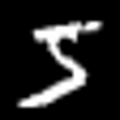

In [3]:
#If we index this dataset, we get a single data point: a PIL image and an Integer
print(ds_train[0])
ds_train[0][0].resize((120,120))

Before we pass samples from the dataset to our model, we would like to normalize the data and convert the samples to PyTorch tensors. We begin by computing the normalization constants, i.e. the mean and the standard deviation of the pixel values in the MNIST training dataset.

In [4]:
# lets get only the images 
ims_train = ds_train.data
ims_train = ims_train.float() / 255.

In [5]:
#########################################################################
# TODO: calculate the mean and std of MNIST images
# hint: to look for operations on pytorch tensor, refer to the official PyTorch docs 
# https://pytorch.org/docs/stable/
#########################################################################
mu = ims_train.mean()
std = ims_train.std()

We can now redefine the train and test datasets with the transform operations that perform normalization and conversion to tensors. 

In [6]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mu, std)
])
ds_train = datasets.MNIST('data', train=True, download=True, transform=transform)
ds_test = datasets.MNIST('data', train=False, download=True, transform=transform)

In [7]:
ds_train[0][0].min(), ds_train[0][0].max()

(tensor(-0.4241), tensor(2.8215))

Next, we will build a dataloader with a batch size of 64 and 4 workers (number of subprocesses that peform the dataloading). Important: you need to shuffle the training data, not the test data.

**NOTE**: if you encounter errors in data loading, try setting `NUM_WORKERS = 0` temporarily to get a more informative error message

In [8]:
BATCH_SIZE = 64
NUM_WORKERS = 4
#########################################################################
# TODO: Build a dataloader for both train and test data.
#########################################################################
dl_train = DataLoader(
    ds_train,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
        shuffle=True,
)

dl_test = DataLoader(
    ds_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

## MLP in Pytorch

Next, we will build our customizable model class. We will replicate the model from our last exercises. However, now, we add another variable called `nLayer` that indicates how many hidden linear layers are in your network.

In [9]:
# These are the parameters to be used
nInput = 784 #The input dimension of the first linear layer
nOutput = 10 #The output dimension of the last linear layer
nLayer = 2 #The number of hidden layers
nHidden = 16 #The dimension of the intermediate outputs (output and input dimension of hidden layers)
act_fn = nn.ReLU() #Activation function

In [10]:
#########################################################################
# TODO: Implement the __init__ of the MLP class. 
# insert the activation after each hidden linear layer, but not after the output layer.
# Return raw logits for F.cross_entropy. The number of hidden layers should be variable!
#########################################################################

class MLP(nn.Module):
    def __init__(self, nInput, nOutput, nLayer, nHidden, act_fn):
        super(MLP, self).__init__()
        layers = []

        layers.append(nn.Linear(nInput, nHidden))

        for i in range(nLayer - 1):
            layers.append(act_fn)
            layers.append(nn.Linear(nHidden, nHidden))

        layers.append(act_fn)
        layers.append(nn.Linear(nHidden, nOutput))
        
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        x = torch.flatten(x, 1)
        return self.model(x)

In [11]:
# Let's test if the forward pass works
# this should print torch.Size([1, 10])
t = torch.randn(1,1,28,28)
mlp = MLP(nInput, nOutput, nLayer, nHidden, act_fn)
mlp(t).shape

torch.Size([1, 10])

In [12]:
mlp

MLP(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=10, bias=True)
  )
)

We already implemented the test function for you

In [13]:
def test(model, dl_test, device='cpu'):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in dl_test:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += F.cross_entropy(output, target, reduction='sum').item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(dl_test.dataset)

    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.3f}%)\n'.format(
        test_loss, correct, len(dl_test.dataset),
        100. * correct / len(dl_test.dataset)))

Now you only need to implement the training and you are good to go

In [14]:
#########################################################################
# TODO: Implement the missing part of the training function. As a loss function, we want to use cross entropy
# It can be called with F.cross_entropy().
# Hint: Pass through the model -> Backpropagate gradients -> Take gradient step
#########################################################################

def train(model, dl_train, optimizer, epoch, log_interval=100, device='cpu'):
    model.train()
    correct = 0
    for batch_idx, (data, target) in enumerate(dl_train):
        data, target = data.to(device), target.to(device)
        
        # first we need to zero the gradient, otherwise PyTorch would accumulate them
        optimizer.zero_grad()    

        output = model(data)
        loss = F.cross_entropy(output, target)
        loss.backward()
        optimizer.step()     

        # stats
        pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
        correct += pred.eq(target.view_as(pred)).sum().item()

        if batch_idx % log_interval == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(dl_train.dataset),
                100. * batch_idx / len(dl_train), loss.item()))

    print('\nTrain set: Last batch loss: {:.4f}, Accuracy: {}/{} ({:.1f}%)\n'.format(
        loss, correct, len(dl_train.dataset),
        100. * correct / len(dl_train.dataset)))

Ok, the setup is almost done. The only missing part is the optimizer. We are going to use Adam.

In [15]:
# reinitialize the mlp, so we can play with parameters right here
mlp = MLP(nInput, nOutput, nLayer, nHidden, act_fn)
optimizer = optim.Adam(mlp.parameters())

In [16]:
epochs = 10
for epoch in range(1, epochs + 1):
    train(mlp, dl_train, optimizer, epoch, log_interval=100)
    test(mlp, dl_test)

print ('Training is finished.')

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.333218
Train Epoch: 1 [6400/60000 (11%)]	Loss: 1.132514
Train Epoch: 1 [12800/60000 (21%)]	Loss: 0.697230
Train Epoch: 1 [19200/60000 (32%)]	Loss: 0.632234
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.534711
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.339998
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.183776
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.221236
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.235930
Train Epoch: 1 [57600/60000 (96%)]	Loss: 0.179098

Train set: Last batch loss: 0.2543, Accuracy: 50182/60000 (83.6%)


Test set: Average loss: 0.3067, Accuracy: 9097/10000 (90.970%)

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.208326
Train Epoch: 2 [6400/60000 (11%)]	Loss: 0.330962
Train Epoch: 2 [12800/60000 (21%)]	Loss: 0.285112
Train Epoch: 2 [19200/60000 (32%)]	Loss: 0.200648
Train Epoch: 2 [25600/60000 (43%)]	Loss: 0.205102
Train Epoch: 2 [32000/60000 (53%)]	Loss: 0.166769
Train Epoch: 2 [38400/60000 (64%)]	Loss: 0.277617
Train Epoch: 2 [44800/60000 (

After training, you should see test accuracies of > **94%** - Can you do some parameter tuning (e.g. increasing the number of layers or hidden dimension) to boost the test accuracy to > **97%**?

In [17]:
#########################################################################
#TODO: modify the parameters below to see which setting that you can get to 97%
#########################################################################
nLayer = 2
nHidden = 128
act_fn = nn.ReLU()

# reinitialize the mlp, so we can play with parameters right here
mlp = MLP(nInput, nOutput, nLayer, nHidden, act_fn)
optimizer = optim.Adam(mlp.parameters())

epochs = 10
for epoch in range(1, epochs + 1):
    train(mlp, dl_train, optimizer, epoch, log_interval=100)
    test(mlp, dl_test)

print ('Training is finished.')

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.309116
Train Epoch: 1 [6400/60000 (11%)]	Loss: 0.214893
Train Epoch: 1 [12800/60000 (21%)]	Loss: 0.194752
Train Epoch: 1 [19200/60000 (32%)]	Loss: 0.221616
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.101729
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.128735
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.132951
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.172481
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.080376
Train Epoch: 1 [57600/60000 (96%)]	Loss: 0.203930

Train set: Last batch loss: 0.1031, Accuracy: 55415/60000 (92.4%)


Test set: Average loss: 0.1316, Accuracy: 9565/10000 (95.650%)

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.092404
Train Epoch: 2 [6400/60000 (11%)]	Loss: 0.094577
Train Epoch: 2 [12800/60000 (21%)]	Loss: 0.162021
Train Epoch: 2 [19200/60000 (32%)]	Loss: 0.115073
Train Epoch: 2 [25600/60000 (43%)]	Loss: 0.047113
Train Epoch: 2 [32000/60000 (53%)]	Loss: 0.071635
Train Epoch: 2 [38400/60000 (64%)]	Loss: 0.086326
Train Epoch: 2 [44800/60000 (

Before you move on to the next exercise, you can further play with the other parameters (learning rate, epochs, a different optimizer, etc.) to get a feeling what can improve or hamper performance. 

## CNN
Alright, we matched our prior performance. Let's surpass it! You will soon see the power of CNN by building a small one yourself. The structure should be as follows



<table>
  <tr><th>CNN Architecture</th></tr>
  <tr><td>Conv2d: <code>C<sub>in</sub>=1</code>, <code>C<sub>out</sub>=32</code>, <code>K=3</code>, <code>S=1</code>, <code>P=0</code></td></tr>
  <tr><td>ReLU</td></tr>
  <tr><td>Conv2d: <code>C<sub>in</sub>=32</code>, <code>C<sub>out</sub>=64</code>, <code>K=3</code>, <code>S=1</code>, <code>P=0</code></td></tr>
  <tr><td>ReLU</td></tr>
  <tr><td>MaxPool2d: <code>K=2</code>, <code>S=2</code>, <code>P=0</code></td></tr>
  <tr><td>Dropout: <code>p=0.25</code></td></tr>
  <tr><td>Linear: <code>C<sub>in</sub>=9216</code>, <code>C<sub>out</sub>=128</code></td></tr>
  <tr><td>ReLU</td></tr>
  <tr><td>Dropout: <code>p=0.5</code></td></tr>
  <tr><td>Linear: <code>C<sub>in</sub>=128</code>, <code>C<sub>out</sub>=10</code></td></tr>
</table>

The layers you will need are: 

`nn.Conv2d,  nn.Linear,  nn.Dropout, nn.MaxPool2d, nn.Flatten`

See https://docs.pytorch.org/docs/stable/nn.html for a full description of different layers. For layers without parameters you can alternatively use these functions in the forward pass:  

`F.max_pool2d, torch.flatten`

The effect is the same - the layers  `nn.MaxPool2d` and `nn.Flatten` are simple wrappers around those functions.

In [18]:
#########################################################################
# TODO: Implement the __init__ and forward method of the CNN class. 
# Hint: do not forget to flatten the appropriate dimensions after the convolutional blocks. 
# A linear layers expects input of the shape (N, F) with batch size N and feature size F 
# whereas convolutional layers produce outputs of shape (N, C, H, W) with batch size N, 
# number of output channels C, output height H and output width W.
#########################################################################

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.25),
            nn.Flatten(start_dim=1),
            nn.Linear(9216, 128),
            nn.ReLU(),
            nn.Dropout(p=0.5),
            nn.Linear(128, 10)
        )


    def forward(self, x):
        return self.model(x)


In [19]:
# Let's test if the forward pass works
# this should print torch.Size([1, 10])
t = torch.randn(1,1,28,28)
cnn = CNN()
cnn(t).shape

torch.Size([1, 10])

Alright, let's train!

In [20]:
optimizer = optim.Adam(cnn.parameters())

In [21]:
epochs = 5
for epoch in range(1, epochs + 1):
    train(cnn, dl_train, optimizer, epoch, log_interval=100)
    test(cnn, dl_test)

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.312868
Train Epoch: 1 [6400/60000 (11%)]	Loss: 0.281928
Train Epoch: 1 [12800/60000 (21%)]	Loss: 0.244476
Train Epoch: 1 [19200/60000 (32%)]	Loss: 0.220217
Train Epoch: 1 [25600/60000 (43%)]	Loss: 0.182320
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.194200
Train Epoch: 1 [38400/60000 (64%)]	Loss: 0.113888
Train Epoch: 1 [44800/60000 (75%)]	Loss: 0.135455
Train Epoch: 1 [51200/60000 (85%)]	Loss: 0.158646
Train Epoch: 1 [57600/60000 (96%)]	Loss: 0.188116

Train set: Last batch loss: 0.0344, Accuracy: 56529/60000 (94.2%)


Test set: Average loss: 0.0396, Accuracy: 9864/10000 (98.640%)

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.055721
Train Epoch: 2 [6400/60000 (11%)]	Loss: 0.109596
Train Epoch: 2 [12800/60000 (21%)]	Loss: 0.059870
Train Epoch: 2 [19200/60000 (32%)]	Loss: 0.057442
Train Epoch: 2 [25600/60000 (43%)]	Loss: 0.006571
Train Epoch: 2 [32000/60000 (53%)]	Loss: 0.011793
Train Epoch: 2 [38400/60000 (64%)]	Loss: 0.075668
Train Epoch: 2 [44800/60000 (

This will probably take a bit longer to train, as a convolutional network is not very efficient on a CPU. The current settings should get you around **99%** accuracy. Nice! 
Again, you should try different hyperparameters and see how far you can push the performance.

### Inline Question

If your model weight is randomly initalized, and no training is done as above. What accuracy do you think the model will get for a 10-class classification task in theory?

**Your answer**: 
Given that the weights are randomly initialized and there is no training done, we can assume the predictions aer also random. Thus, we can expect and accuracy of 10%, that is each class has 1/10 of being predicted.

## Training on CIFAR10

Now we are going to move to something more challenging - CIFAR10. We can reuse most of the code above. Thankfully, CIFAR is also a popular dataset, so we can again make use of a PyTorch convience function.

In [23]:
ds_train = datasets.CIFAR10(root='./data', train=True, download=True)

As in the previous exercise, the dataset is not normalized yet, so we need to calculate the normalization constants.

In [24]:
ims_train = torch.tensor(ds_train.data)
ims_train = ims_train.float() / 255.

In [25]:
#########################################################################
# DONE: calculate the mean and std of CIFAR
# hint: We want the mean and std of the channel dimension, these should
# be 3 dimensional
#########################################################################
mu = ims_train.mean((0,1,2))
std = ims_train.std((0,1,2))


For CIFAR we want to additionally apply some data augmentation transforms to the samples in our dataset for improved generalization. You can find a comprehensive overview of available transforms under the following link.

https://docs.pytorch.org/vision/0.8/transforms.html

In [26]:
BATCH_SIZE = 128
NUM_WORKERS = 4 # if you encounter some unexpected errors in data loading, try setting `NUM_WORKERS = 0`
#########################################################################
# TODO: Implement the proper transforms for the training and test dataloaders. 
# Then build train and test dataloaders with batch size 128 and 4 workers
#
# These are the transforms that should be applied.
# Train: 
# - Apply a random crop with size 32 on a padded version of the image with P=4
# - Flip the image horizontally with a probability of 40 %
# - Transform to a Tensor
# - Normalize with the constants calculated above
# Test: 
# - Transform to a Tensor
# - Normalize with the constants calculated above
#########################################################################
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.4),
    transforms.ToTensor(),
    transforms.Normalize(mu, std)
])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mu, std)
])

ds_train = datasets.CIFAR10('./data', train=True, download=True, transform=transform_train)
ds_test = datasets.CIFAR10('./data', train=False, download=True, transform=transform_test)

dl_train = DataLoader(
    ds_train,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
        shuffle=True,
)
dl_test = DataLoader(
    ds_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

Setting up the  optimizer, this time we use stochastic gradient descent (SGD). The scheduler adapts the learning rate during training.

In [27]:
cnn = CNN()
optimizer = optim.SGD(cnn.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

In [28]:
epochs = 5
for epoch in range(1, epochs + 1):
    train(cnn, dl_train, optimizer, epoch, log_interval=100)
    test(cnn, dl_test)    
    scheduler.step()

RuntimeError: Given groups=1, weight of size [32, 1, 3, 3], expected input[128, 3, 32, 32] to have 1 channels, but got 3 channels instead

This will not work. You should see the following error message

```
Given groups=1, weight of size [32, 1, 3, 3], expected input[128, 3, 32, 32] to have 1 channels, but got 3 channels instead
```

This error is telling us that something is not right in the definition of our model. Copy the CNN class from above and make changes, so the training works.

In [ ]:
#########################################################################
# TODO: Adapt the definition from the CNN class above to work on CIFAR.
# You can copy and run the following prompt for evaluation:
# CNN()(torch.randn(1,3,32,32)).shape
# It should print 'torch.Size([1, 10])'
# Hint: You need to change 2 things. 
#########################################################################

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.model = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=0),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout(p=0.1),
            nn.Flatten(start_dim=1),
            nn.Linear(12544, 128),
            nn.ReLU(),
            nn.Dropout(p=0.1),
            nn.Linear(128, 10)
        )
        

    def forward(self, x):
        return self.model(x)

Let's try again

In [ ]:
cnn = CNN()
optimizer = optim.SGD(cnn.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

epochs = 20
for epoch in range(1, epochs + 1):
    train(cnn, dl_train, optimizer, epoch, log_interval=100)
    test(cnn, dl_test)    
    scheduler.step()

This should give 40 - 50 % - and if you are not already on Colab it might cause your laptop to stress out a bit. The performance is a lot better than random, but we can definitely do better.

### Have fun with GPUs (Bonus Exercises)
The rest of the exercise is not graded but you can have some fun exploring the capability of these models further. :)



If you didn't already, move to Google Colab. To use a GPU, follow on the collaboratory menu tabs, "Runtime" => "Change runtime type" and set it to GPU. Then run the same training loop but now on GPU. To do so, we need to explicitly move our tensors to a GPU device - Note that our training loop as define above takes a device parameter as input and alreadt does the job for us.

It's as easy as:

In [29]:
device = 'cuda'
if device == 'cuda': torch.backends.cudnn.benchmark = True # additional speed up

cnn = CNN()
cnn = cnn.to(device)
optimizer = optim.SGD(cnn.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

epochs = 10
for epoch in range(1, epochs + 1):
    train(cnn, dl_train, optimizer, epoch, log_interval=100, device=device)
    test(cnn, dl_test, device=device)    
    scheduler.step()

RuntimeError: Given groups=1, weight of size [32, 1, 3, 3], expected input[128, 3, 32, 32] to have 1 channels, but got 3 channels instead

This should be way faster now. But the true advantage of the GPU is that we can use much bigger models now and still train them in a reasonable amount of time. PyTorch is again very handy. The torchvision library comes with varies state-of-the-art model architectures, some of which you have seen in the lecture.

In [30]:
from torchvision.models import resnet18, ResNet18_Weights

In [31]:
cnn = resnet18(weights=ResNet18_Weights.DEFAULT)
print(cnn)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/sebas/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:02<00:00, 23.0MB/s]

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

Looks scary! But the only thing you need to change to make it work on CIFAR is the last layer.
Currently the last layer is:
```
  (fc): Linear(in_features=512, out_features=1000, bias=True)
```
out_features is the number of classes. The pretrained model was trained on ImageNet, a dataset with 1000 classes. Adapt this layer for the 10 CIFAR-10 classes. Keep the output as raw logits: our training function uses `F.cross_entropy`, which applies log-softmax internally. The first use of pretrained weights requires an internet connection to download them. Keep the existing first convolution to retain its pretrained weights; changing it for 32x32 inputs is optional. 

In [32]:
#########################################################################
# TODO: Adapt Resnet to work on CIFAR
#########################################################################

cnn.fc = nn.Linear(cnn.fc.in_features, 10)


In [33]:
# This should print 'torch.Size([16, 10])'
cnn(torch.randn(16,3,32,32)).shape

torch.Size([16, 10])

In [34]:
device = 'cuda'
if device == 'cuda': torch.backends.cudnn.benchmark = True # this gives us additional speed up

cnn = cnn.to(device)
optimizer = optim.SGD(cnn.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=200)

epochs = 50
for epoch in range(1, epochs + 1):
    train(cnn, dl_train, optimizer, epoch, log_interval=100, device=device)
    test(cnn, dl_test, device=device)    
    scheduler.step()

Train Epoch: 1 [0/50000 (0%)]	Loss: 2.707818
Train Epoch: 1 [12800/50000 (26%)]	Loss: 2.728699
Train Epoch: 1 [25600/50000 (51%)]	Loss: 2.673148
Train Epoch: 1 [38400/50000 (77%)]	Loss: 2.270544

Train set: Last batch loss: 1.7828, Accuracy: 9606/50000 (19.2%)


Test set: Average loss: 1.9638, Accuracy: 2750/10000 (27.500%)

Train Epoch: 2 [0/50000 (0%)]	Loss: 2.031300
Train Epoch: 2 [12800/50000 (26%)]	Loss: 1.812412
Train Epoch: 2 [25600/50000 (51%)]	Loss: 1.765927
Train Epoch: 2 [38400/50000 (77%)]	Loss: 1.721386

Train set: Last batch loss: 1.7521, Accuracy: 16169/50000 (32.3%)


Test set: Average loss: 1.5736, Accuracy: 4224/10000 (42.240%)

Train Epoch: 3 [0/50000 (0%)]	Loss: 1.620284
Train Epoch: 3 [12800/50000 (26%)]	Loss: 1.637309
Train Epoch: 3 [25600/50000 (51%)]	Loss: 1.848946
Train Epoch: 3 [38400/50000 (77%)]	Loss: 1.554149

Train set: Last batch loss: 1.5076, Accuracy: 20995/50000 (42.0%)


Test set: Average loss: 1.5414, Accuracy: 4484/10000 (44.840%)

Train Epoch: 4 [0

This should get us well above 75%, the best we got was ~ 80%.

If you would like to explore further, you can now use different torchvision architectures, optimizers (Adam is always a good choice), data augmentation techniques, and hyperparameter search to achieve a test accuracy of >90 %